# Do Domain-Trained Word Embeddings Beat GloVe?
### Sentiment classification on ~360k de-duplicated Amazon food reviews

General-purpose embeddings such as GloVe are trained on billions of tokens of Wikipedia and news text. Word2Vec
embeddings trained on the reviews themselves see far less text, but text from exactly the right domain. This
notebook asks which starting point helps a neural sentiment classifier more, and under what conditions.

The classifier is held fixed (a bidirectional LSTM). Only its embedding layer changes:

| Initialisation | Source |
|---|---|
| Random | learned from scratch |
| Skip-gram | Word2Vec trained on the training reviews |
| CBOW | Word2Vec trained on the training reviews |
| GloVe 6B | pretrained on Wikipedia + Gigaword (6B tokens) |

Each pretrained option is tested **frozen** and **fine-tuned**, with three seeds per configuration, and again with
much smaller labelled training sets.

**Contents**
1. Data: filtering, duplicate removal and splits
2. Why duplicates matter: a leakage check
3. Training the domain embeddings
4. Comparing the embedding spaces
5. Classifier and training protocol
6. Main comparison
7. When labelled data is scarce
8. Error analysis
9. Conclusions

## Setup

In [1]:
import os, re, time, random, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix
warnings.filterwarnings("ignore")

DATA = "../data"
SEED = 42
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seed(SEED)

DEVICE = torch.device("mps" if torch.backends.mps.is_available()
                      else "cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("device:", DEVICE, "| torch", torch.__version__)

device: mps | torch 2.12.1


## 1. Data

Reviews with 1–2 stars are labelled **negative** and 4–5 stars **positive**. 3-star reviews are dropped as
ambiguous. The dataset contains many exact duplicates: the same review text is often listed under several
variants of one product. These are removed *before* splitting, so that no test review also appears in training.

In [2]:
raw = pd.read_csv(f"{DATA}/Reviews.csv", usecols=["UserId", "Score", "Text"])
df = raw[raw.Score != 3].copy()
df["label"] = (df.Score >= 4).astype(int)
n_before = len(df)
df = df.drop_duplicates("Text").reset_index(drop=True)

print(f"raw reviews:           {len(raw):,}")
print(f"after dropping 3-star: {n_before:,}")
print(f"after de-duplication:  {len(df):,}  ({1 - len(df)/n_before:.1%} were duplicates)")
print(f"positive share:        {df.label.mean():.1%}")

raw reviews:           568,454
after dropping 3-star: 525,814
after de-duplication:  363,836  (30.8% were duplicates)
positive share:        84.3%


In [3]:
def tokenize(text):
    text = text.lower().replace("<br />", " ")
    text = re.sub(r"https?://\S+", " ", text)
    text = text.replace("n't", " n't")          # matches GloVe's tokenisation: do n't, ca n't
    return re.findall(r"n't|[a-z]+|[!?]", text)

t0 = time.time()
df["tokens"] = df.Text.map(tokenize)
lens = df.tokens.map(len)
print(f"tokenised in {time.time()-t0:.0f}s | median {lens.median():.0f} tokens, "
      f"90th pct {lens.quantile(.9):.0f}, 95th pct {lens.quantile(.95):.0f}")

tokenised in 3s | median 57 tokens, 90th pct 159, 95th pct 214


**Splits.** A fixed test set (20,000) and validation set (10,000) are drawn first, stratified by label. The remaining
reviews form a *pool*. The domain embeddings are trained on the whole pool (text only, no labels). The classifiers
are trained on a labelled sample of 50,000 reviews from the same pool, which mirrors the common situation of plenty
of raw text but limited labelled data.

In [4]:
rest, test = train_test_split(df, test_size=20_000, stratify=df.label, random_state=SEED)
pool, val = train_test_split(rest, test_size=10_000, stratify=rest.label, random_state=SEED)
train = pool.sample(n=50_000, random_state=SEED)

for name, part in [("pool (embeddings)", pool), ("train (labelled)", train), ("val", val), ("test", test)]:
    print(f"{name:18s} {len(part):>8,}   positive {part.label.mean():.1%}")
assert not set(test.Text) & set(pool.Text)

pool (embeddings)   333,836   positive 84.3%
train (labelled)     50,000   positive 84.3%
val                  10,000   positive 84.3%
test                 20,000   positive 84.3%


## 2. Why duplicates matter: a leakage check

To show what the de-duplication step protects against, the same TF-IDF + logistic-regression model is trained
twice on 100,000 reviews: once sampled from the raw data, once from the de-duplicated data. Both use a random
80/20 split.

In [5]:
def tfidf_lr(train_text, train_y, test_text):
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=300_000, sublinear_tf=True)
    clf = LogisticRegression(max_iter=2000, C=4.0)
    clf.fit(vec.fit_transform(train_text), train_y)
    return clf.predict_proba(vec.transform(test_text))[:, 1]

raw_bin = raw[raw.Score != 3].assign(label=lambda d: (d.Score >= 4).astype(int))
rows = []
for name, source in [("with duplicates", raw_bin), ("de-duplicated", df)]:
    s = source.sample(n=100_000, random_state=SEED)
    tr, te = train_test_split(s, test_size=0.2, stratify=s.label, random_state=SEED)
    p = tfidf_lr(tr.Text, tr.label, te.Text)
    seen = te.Text.isin(set(tr.Text)).mean()
    rows.append({"data": name, "test reviews also in train": f"{seen:.1%}",
                 "macro-F1": f1_score(te.label, p >= 0.5, average="macro"),
                 "negative-class F1": f1_score(te.label, p >= 0.5, pos_label=0)})
leak = pd.DataFrame(rows).set_index("data").round(4)
leak

,test reviews also in train,macro-F1,negative-class F1
data,,,
with duplicates,19.5%,0.8913,0.8133
de-duplicated,0.0%,0.8777,0.7897


**Duplicates inflate the scores.** In a random split of the raw data, 19.5% of test reviews also appear word for word
in the training set. The same model then scores 0.891 macro-F1 instead of 0.878, and 0.813 negative-class F1 instead of
0.790. The gap is small in absolute terms, but it is larger than most of the differences between embeddings measured
below, so every later result uses the de-duplicated data.

## 3. Training the domain embeddings

Skip-gram and CBOW are trained with identical settings on the pool of reviews. 100 dimensions are used throughout so
that all three embeddings, including GloVe 6B-100d, have the same size.

In [6]:
# gensim 4.4 with recent NumPy prints occasional harmless 'Exception ignored in our_dot_float'
# warnings from its BLAS helper; they are omitted from the saved output. The nearest-neighbour
# checks in Section 4 confirm that the vectors are sound.
W2V = dict(vector_size=100, window=5, min_count=5, negative=5, epochs=5,
           workers=os.cpu_count(), seed=SEED)
sentences = pool.tokens.tolist()
n_tokens = sum(map(len, sentences))
print(f"embedding corpus: {len(sentences):,} reviews, {n_tokens/1e6:.1f}M tokens")

w2v, w2v_time = {}, {}
for name, sg in [("Skip-gram", 1), ("CBOW", 0)]:
    t0 = time.time()
    w2v[name] = Word2Vec(sentences, sg=sg, **W2V).wv
    w2v_time[name] = time.time() - t0
    print(f"{name:9s} {w2v_time[name]:6.1f}s   vocabulary {len(w2v[name]):,}")

embedding corpus: 333,836 reviews, 26.7M tokens


Skip-gram   42.6s   vocabulary 32,505


CBOW        16.6s   vocabulary 32,505


In [7]:
# Classifier vocabulary: words seen at least twice in the labelled training set
PAD, UNK = 0, 1
counts = Counter(t for toks in train.tokens for t in toks)
itos = ["<pad>", "<unk>"] + [w for w, c in counts.most_common() if c >= 2]
stoi = {w: i for i, w in enumerate(itos)}
V = len(itos)

glove = {}
with open(f"{DATA}/glove.6B.100d.txt", encoding="utf8") as f:
    for line in f:
        w, rest_ = line.split(" ", 1)
        if w in stoi:
            glove[w] = np.asarray(rest_.split(), dtype=np.float32)

sources = {"Skip-gram": w2v["Skip-gram"], "CBOW": w2v["CBOW"], "GloVe": glove}
test_counts = Counter(t for toks in test.tokens for t in toks)
n_test = sum(test_counts.values())
cov = []
for name, src in sources.items():
    cov.append({"embedding": name,
                "vocab words covered": f"{sum(w in src for w in itos[2:]) / (V-2):.1%}",
                "test tokens covered": f"{sum(c for w, c in test_counts.items() if w in src) / n_test:.1%}"})
print(f"classifier vocabulary: {V:,} words")
pd.DataFrame(cov).set_index("embedding")

classifier vocabulary: 23,753 words


,vocab words covered,test tokens covered
embedding,,
Skip-gram,94.1%,99.6%
CBOW,94.1%,99.6%
GloVe,89.4%,98.9%


## 4. Comparing the embedding spaces

Nearest neighbours by cosine similarity, restricted to the classifier vocabulary so that all three embeddings are
searched over the same words.

In [8]:
def matrix_for(src, words):
    return np.stack([src[w] for w in words])

def neighbours(src, word, k=5):
    words = [w for w in itos[2:] if w in src]
    M = matrix_for(src, words)
    M = M / np.linalg.norm(M, axis=1, keepdims=True)
    q = M[words.index(word)]
    order = np.argsort(-(M @ q))
    return ", ".join(words[i] for i in order[1:k+1])

PROBES = ["delicious", "stale", "bland", "cheap", "refund", "crunchy"]
pd.DataFrame({name: [neighbours(src, w) for w in PROBES] for name, src in sources.items()},
             index=PROBES)

,Skip-gram,CBOW,GloVe
delicious,"delicous, yummy, tasty, scrumptious, fabulous","yummy, delicous, fabulous, delish, scrumptious","tasty, spicy, dessert, savory, refreshing"
stale,"rancid, moldy, unedible, discolored, musty","rancid, moldy, discolored, inedible, chalky","moldy, tiresome, gooey, musty, rancid"
bland,"tasteless, unpalatable, flavorless, boring, wa...","watery, flavorless, tasteless, gritty, unpalat...","dull, straightforward, charming, predictable, ..."
cheap,"crappy, inexpensive, crummy, overpriced, cheep","overpriced, expensive, good, inexpensive, bad","inexpensive, cheaper, expensive, affordable, easy"
refund,"return, refunded, credit, apology, reply","credit, reply, email, return, response","refunds, payment, refunded, fees, checks"
crunchy,"crispy, crunch, cruchy, chewy, oaty","crispy, chewy, crunch, crisp, chewey","chewy, crispy, creamy, buttery, nutty"


In [9]:
# How far apart are sentiment words? Mean cosine similarity within and across two small word sets.
POS = ["delicious", "tasty", "excellent", "wonderful", "perfect", "great", "yummy", "fantastic"]
NEG = ["disgusting", "awful", "terrible", "horrible", "worst", "bad", "nasty", "gross"]

def mean_cos(src, a, b, same):
    sims = [np.dot(src[x], src[y]) / np.linalg.norm(src[x]) / np.linalg.norm(src[y])
            for i, x in enumerate(a) for j, y in enumerate(b) if not same or i < j]
    return np.mean(sims)

sep = pd.DataFrame([{"embedding": n,
                     "within positive": mean_cos(s, POS, POS, True),
                     "within negative": mean_cos(s, NEG, NEG, True),
                     "positive vs negative": mean_cos(s, POS, NEG, False)}
                    for n, s in sources.items()]).set_index("embedding").round(3)
sep

,within positive,within negative,positive vs negative
embedding,,,
Skip-gram,0.694,0.750,0.365
CBOW,0.670,0.722,0.311
GloVe,0.475,0.544,0.341


**The domain embeddings speak "food review".** Their neighbours are food-specific and even absorb common misspellings
(*delicous*, *cruchy*, *cheep*), which GloVe cannot represent at all. GloVe's neighbours reflect news and Wikipedia usage:
*bland* sits next to *charming* and *straightforward*, *stale* next to *tiresome*. CBOW gives broader neighbourhoods than
Skip-gram (*cheap* → *overpriced*, *good*, *bad*), which is expected from averaging the context.

**Sentiment structure.** Sentiment words of the same polarity are far closer in the domain spaces (0.67–0.75 mean
cosine) than in GloVe (0.48–0.54), while the similarity between opposite polarities is about the same in all three
(0.31–0.37). The gap between "same polarity" and "opposite polarity" is therefore 2–3× wider in the domain
embeddings, which is exactly the property a sentiment classifier can exploit.

Coverage also favours the domain embeddings: 94% of the classifier vocabulary (99.6% of test tokens) against 89%
(98.9%) for GloVe.

## 5. Classifier and training protocol

* **Model:** embedding (100-d) → dropout → one-layer BiLSTM (128 per direction) → masked max-pooling over time →
  dropout → linear output. About 2.4M parameters in the embedding table and 0.24M in the rest.
* **Input:** the first 160 tokens of each review (covers about 90% of reviews completely).
* **Pretrained initialisation:** each vocabulary word takes its pretrained vector when available. Words without one
  are drawn at random with the same scale as the pretrained vectors.
* **Training:** Adam (lr 2e-3), batch 256, gradient clipping at 1.0, up to 8 epochs with early stopping on
  validation macro-F1 (patience 2).
* **Evaluation:** the decision threshold is tuned on validation for macro-F1 and applied unchanged to the test set.
  Because 85% of reviews are positive, accuracy is not reported. The headline metric is **macro-F1**, and
  **negative-class F1** is reported separately because negative reviews are the costly ones to miss.

In [10]:
MAX_LEN, BATCH = 160, 256

def encode(token_lists):
    X = np.zeros((len(token_lists), MAX_LEN), dtype=np.int64)
    for i, toks in enumerate(token_lists):
        ids = [stoi.get(t, UNK) for t in toks[:MAX_LEN]]
        X[i, :len(ids)] = ids
    return torch.from_numpy(X)

X_val, y_val = encode(val.tokens.tolist()), val.label.values
X_test, y_test = encode(test.tokens.tolist()), test.label.values

def init_matrix(name, seed):
    rng = np.random.default_rng(seed)
    if name == "Random":
        M = rng.normal(0, 0.1, (V, 100)).astype(np.float32)
    else:
        src = sources[name]
        known = np.stack([src[w] for w in itos[2:] if w in src])
        M = rng.normal(0, known.std(), (V, 100)).astype(np.float32)
        for i, w in enumerate(itos):
            if i > 1 and w in src:
                M[i] = src[w]
    M[PAD] = 0
    return torch.from_numpy(M)

class BiLSTMClassifier(nn.Module):
    def __init__(self, emb, freeze, hidden=128, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding.from_pretrained(emb.clone(), freeze=freeze, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb.shape[1], hidden, batch_first=True, bidirectional=True)
        self.out = nn.Linear(2 * hidden, 1)

    def forward(self, x):
        h, _ = self.lstm(self.drop(self.emb(x)))
        h = h.masked_fill((x == PAD).unsqueeze(-1), -1e4)
        return self.out(self.drop(h.max(dim=1).values)).squeeze(-1)

@torch.no_grad()
def predict(model, X):
    model.eval()
    return np.concatenate([torch.sigmoid(model(X[i:i+1024].to(DEVICE))).cpu().numpy()
                           for i in range(0, len(X), 1024)])

def best_threshold(y, p):
    grid = np.arange(0.05, 0.96, 0.01)
    return grid[np.argmax([f1_score(y, p >= t, average="macro") for t in grid])]

def evaluate(y, p, t):
    return {"macro_f1": f1_score(y, p >= t, average="macro"),
            "neg_f1": f1_score(y, p >= t, pos_label=0),
            "auc": roc_auc_score(y, p)}

def run(init, freeze, train_df, seed, max_epochs=8, patience=2, batch=BATCH):
    set_seed(seed)
    X, y = encode(train_df.tokens.tolist()), torch.tensor(train_df.label.values, dtype=torch.float32)
    model = BiLSTMClassifier(init_matrix(init, seed), freeze).to(DEVICE)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=2e-3)
    loss_fn = nn.BCEWithLogitsLoss()
    best, best_state, wait, t0 = -1, None, 0, time.time()
    for epoch in range(1, max_epochs + 1):
        model.train()
        perm = torch.randperm(len(X))
        for i in range(0, len(X), batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            loss = loss_fn(model(X[idx].to(DEVICE)), y[idx].to(DEVICE))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        score = f1_score(y_val, predict(model, X_val) >= 0.5, average="macro")
        if score > best:
            best, best_epoch, wait = score, epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    p_val = predict(model, X_val)
    t = best_threshold(y_val, p_val)
    res = {"init": init, "frozen": freeze, "n_train": len(train_df), "seed": seed,
           "best_epoch": best_epoch, "train_s": time.time() - t0, "threshold": t,
           **evaluate(y_test, predict(model, X_test), t)}
    return res, model

## 6. Main comparison

Seven configurations × three seeds, each trained on the same 50,000 labelled reviews. A TF-IDF + logistic-regression
model trained on the same data is included as a non-neural reference point.

In [11]:
CONFIGS = [("Random", False)] + [(n, f) for n in ["Skip-gram", "CBOW", "GloVe"] for f in (True, False)]
SEEDS = [0, 1, 2]

results, models = [], {}
for init, freeze in CONFIGS:
    for seed in SEEDS:
        res, m = run(init, freeze, train, seed)
        results.append(res)
        if seed == 0:
            models[(init, freeze)] = m
        print(f"{init:9s} {'frozen' if freeze else 'tuned ':6s} seed {seed}  macro-F1 {res['macro_f1']:.4f}  "
              f"neg-F1 {res['neg_f1']:.4f}  epoch {res['best_epoch']}  {res['train_s']:.0f}s")
main = pd.DataFrame(results)

Random    tuned  seed 0  macro-F1 0.8579  neg-F1 0.7598  epoch 3  70s


Random    tuned  seed 1  macro-F1 0.8540  neg-F1 0.7509  epoch 4  81s


Random    tuned  seed 2  macro-F1 0.8554  neg-F1 0.7562  epoch 3  67s


Skip-gram frozen seed 0  macro-F1 0.8807  neg-F1 0.7996  epoch 6  99s


Skip-gram frozen seed 1  macro-F1 0.8873  neg-F1 0.8083  epoch 7  99s


Skip-gram frozen seed 2  macro-F1 0.8885  neg-F1 0.8124  epoch 8  97s


... (11 outputs left out)

GloVe     frozen seed 2  macro-F1 0.8658  neg-F1 0.7744  epoch 7  99s


GloVe     tuned  seed 0  macro-F1 0.8705  neg-F1 0.7827  epoch 4  80s


GloVe     tuned  seed 1  macro-F1 0.8729  neg-F1 0.7860  epoch 4  80s


GloVe     tuned  seed 2  macro-F1 0.8614  neg-F1 0.7650  epoch 8  107s


In [12]:
p_lr_val = tfidf_lr(train.Text, train.label, val.Text)
t_lr = best_threshold(y_val, p_lr_val)
p_lr = tfidf_lr(train.Text, train.label, test.Text)
lr_res = evaluate(y_test, p_lr, t_lr)

main["config"] = main.init + np.where(main.init == "Random", "", np.where(main.frozen, " (frozen)", " (fine-tuned)"))
summary = (main.groupby("config", sort=False)[["macro_f1", "neg_f1", "auc", "best_epoch", "train_s"]]
               .agg(["mean", "std"]))
table = pd.DataFrame({
    "macro-F1": summary.macro_f1["mean"].map("{:.4f}".format) + " ± " + summary.macro_f1["std"].map("{:.4f}".format),
    "negative F1": summary.neg_f1["mean"].map("{:.4f}".format) + " ± " + summary.neg_f1["std"].map("{:.4f}".format),
    "ROC-AUC": summary.auc["mean"].map("{:.4f}".format),
    "best epoch": summary.best_epoch["mean"].round(1),
    "train time (s)": summary.train_s["mean"].round(0).astype(int),
})
table.loc["TF-IDF + logistic regression"] = [f"{lr_res['macro_f1']:.4f}", f"{lr_res['neg_f1']:.4f}",
                                            f"{lr_res['auc']:.4f}", "–", "–"]
table.sort_values("macro-F1", ascending=False)

,macro-F1,negative F1,ROC-AUC,best epoch,train time (s)
config,,,,,
CBOW (frozen),0.8912 ± 0.0022,0.8170 ± 0.0029,0.9733,7.3,103
CBOW (fine-tuned),0.8866 ± 0.0041,0.8085 ± 0.0064,0.9720,4.0,81
Skip-gram (frozen),0.8855 ± 0.0042,0.8068 ± 0.0065,0.9702,7.0,98
TF-IDF + logistic regression,0.8843,0.8051,0.9701,–,–
Skip-gram (fine-tuned),0.8757 ± 0.0035,0.7903 ± 0.0066,0.9646,5.0,89
GloVe (frozen),0.8685 ± 0.0023,0.7788 ± 0.0038,0.9620,7.7,100
GloVe (fine-tuned),0.8683 ± 0.0060,0.7779 ± 0.0113,0.9616,5.3,89
Random,0.8558 ± 0.0020,0.7556 ± 0.0045,0.9564,3.3,73


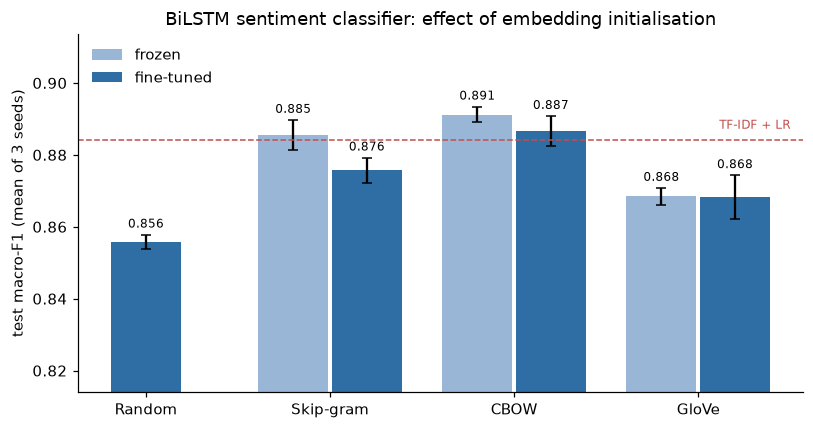

In [13]:
order = ["Random", "Skip-gram", "CBOW", "GloVe"]
fig, ax = plt.subplots(figsize=(7.5, 4))
x = np.arange(len(order))
for k, (label, freeze, color, off) in enumerate([("frozen", True, "#9ab6d6", -0.2),
                                                  ("fine-tuned", False, "#2f6ea5", 0.2)]):
    sub = main[(main.frozen == freeze) | (main.init == "Random")] if not freeze else main[main.frozen]
    g = sub.groupby("init").macro_f1.agg(["mean", "std"]).reindex(order)
    xs = np.where(np.array(order) == "Random", 0.0, x + off)
    ax.bar(xs, g["mean"], 0.38, yerr=g["std"], capsize=3, color=color, label=label)
    for xi, m, sd in zip(xs, g["mean"], g["std"]):
        if not np.isnan(m):
            ax.text(xi, m + sd + 0.002, f"{m:.3f}", ha="center", fontsize=8)
ax.axhline(lr_res["macro_f1"], color="#c0504d", ls="--", lw=1)
ax.text(len(order) - 0.5, lr_res["macro_f1"] + 0.003, "TF-IDF + LR", color="#c0504d", ha="right", fontsize=8)
ax.set_xticks(x, order)
lo = main.macro_f1.min()
ax.set_ylim(lo - 0.04, main.macro_f1.max() + 0.02)
ax.set_ylabel("test macro-F1 (mean of 3 seeds)")
ax.set_title("BiLSTM sentiment classifier: effect of embedding initialisation")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

**Domain embeddings win clearly.** Initialising from CBOW or Skip-gram raises test macro-F1 from 0.856 (random) to
0.886–0.891, and negative-class F1 from 0.756 to 0.807–0.817. GloVe also helps, but less than half as much (0.868). The
general-purpose vectors, trained on roughly 200× more text, lose to vectors trained on 27M tokens of the right domain.

**Freezing is at least as good as fine-tuning.** For all three pretrained embeddings the frozen version scores the same
or higher (CBOW +0.005, Skip-gram +0.010, GloVe ±0.000). With 50,000 labelled reviews, updating 2.4M embedding weights
mostly adds noise. The fine-tuned runs also peak earlier (epoch 4–5) and then start to overfit.

**CBOW edges out Skip-gram** here, and it trained 2.6× faster (17 s vs 43 s). This matches the expectation that
CBOW's averaged context favours frequent words, which carry most of the sentiment signal in reviews.

**A strong linear baseline is hard to beat.** TF-IDF + logistic regression reaches 0.884. Only the best BiLSTM
configuration (frozen CBOW, 0.891 ± 0.002) is clearly above it; Skip-gram and fine-tuned CBOW are within noise of it,
and GloVe and random initialisation are below it.

The ranking (CBOW ≥ Skip-gram > GloVe > random, frozen ≥ fine-tuned) was the same in two complete runs of this
notebook; individual means moved by up to 0.005 between runs.

## 7. When labelled data is scarce

Pretrained embeddings are expected to matter most when there are few labelled examples. The four fine-tuned
configurations are retrained on 1,000, 5,000 and 20,000 labelled reviews, three seeds each. So that the small sets still
get enough gradient updates, they use a batch size of 32 (1,000 and 5,000) or 128 (20,000) and a longer epoch budget
with patience 4. The 50,000 point is taken from the main run.

In [14]:
SIZES = {1_000: 32, 5_000: 32, 20_000: 128}
small = []
for n, batch in SIZES.items():
    sub = train.sample(n=n, random_state=SEED)
    for init in order:
        scores = []
        for seed in SEEDS:
            res, _ = run(init, False, sub, seed, max_epochs=30, patience=4, batch=batch)
            small.append(res); scores.append(res["macro_f1"])
        print(f"n={n:>6,}  {init:9s}  " + "  ".join(f"{x:.4f}" for x in scores))
curve = pd.concat([pd.DataFrame(small), main[~main.frozen]])
curve_stats = curve.groupby(["n_train", "init"]).macro_f1.agg(["mean", "std"])
curve_tab = curve_stats["mean"].unstack()[order]
curve_std = curve_stats["std"].unstack()[order]
(curve_tab.round(4).astype(str) + " ± " + curve_std.round(4).astype(str))

n= 1,000  Random     0.7166  0.7173  0.7080


n= 1,000  Skip-gram  0.7880  0.7845  0.7824


n= 1,000  CBOW       0.7980  0.7596  0.7944


n= 1,000  GloVe      0.7516  0.7631  0.7645


n= 5,000  Random     0.7881  0.7858  0.7810


n= 5,000  Skip-gram  0.8121  0.8243  0.8143


... (3 outputs left out)

n=20,000  Skip-gram  0.8491  0.8483  0.8555


n=20,000  CBOW       0.8771  0.8742  0.8764


n=20,000  GloVe      0.8483  0.8534  0.8456


init,Random,Skip-gram,CBOW,GloVe
n_train,,,,
1000,0.714 ± 0.0052,0.785 ± 0.0028,0.784 ± 0.0212,0.7597 ± 0.007
5000,0.785 ± 0.0036,0.8169 ± 0.0065,0.8423 ± 0.0018,0.8144 ± 0.0058
20000,0.8272 ± 0.0047,0.851 ± 0.004,0.8759 ± 0.0015,0.8491 ± 0.004
50000,0.8558 ± 0.002,0.8757 ± 0.0035,0.8866 ± 0.0041,0.8683 ± 0.006


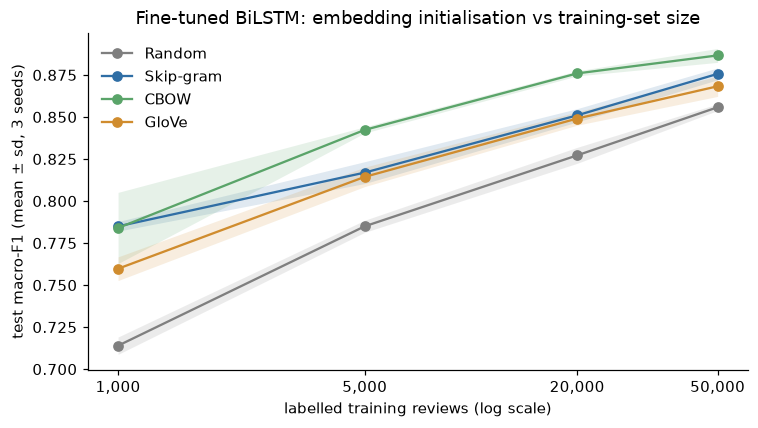

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
colors = {"Random": "#7f7f7f", "Skip-gram": "#2f6ea5", "CBOW": "#5aa469", "GloVe": "#d08c2e"}
for init in order:
    ax.plot(curve_tab.index, curve_tab[init], marker="o", label=init, color=colors[init])
    ax.fill_between(curve_tab.index, curve_tab[init] - curve_std[init], curve_tab[init] + curve_std[init],
                    color=colors[init], alpha=0.15, lw=0)
ax.set_xscale("log")
ax.set_xticks(curve_tab.index, [f"{n:,}" for n in curve_tab.index])
ax.minorticks_off()
ax.set_xlabel("labelled training reviews (log scale)")
ax.set_ylabel("test macro-F1 (mean ± sd, 3 seeds)")
ax.set_title("Fine-tuned BiLSTM: embedding initialisation vs training-set size")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Pretrained embeddings matter most when labels are scarce.** With 1,000 labelled reviews, domain embeddings lift
macro-F1 from 0.714 (random) to 0.784–0.785, a gain of +0.07; GloVe gains +0.046. With 50,000 labels the gain shrinks
to +0.02–0.03.

Put differently, **pretraining on unlabelled reviews is worth more than doubling the labelled data**: CBOW with
5,000 labels (0.842) beats random initialisation with 20,000 (0.827), and CBOW with 20,000 (0.876) beats random
initialisation with 50,000 (0.856). Raw review text is cheap; labels are not.

CBOW's 1,000-review result has the widest spread across seeds (± 0.021), so the Skip-gram / CBOW order at that size is
not meaningful. From 5,000 reviews on, CBOW is consistently ahead.

## 8. Error analysis

The best configuration from Section 6 (seed 0) is compared with the TF-IDF baseline by review length and by whether
the review contains a negation.

In [16]:
best_cfg = main.groupby(["init", "frozen"]).macro_f1.mean().idxmax()
best_model = models[best_cfg]
t_best = main[(main.init == best_cfg[0]) & (main.frozen == best_cfg[1]) & (main.seed == 0)].threshold.iloc[0]
p_best = predict(best_model, X_test)
print("best configuration:", best_cfg[0], "frozen" if best_cfg[1] else "fine-tuned")

cm = confusion_matrix(y_test, p_best >= t_best)
print(pd.DataFrame(cm, index=["true negative", "true positive"], columns=["pred negative", "pred positive"]))

an = test[["Text", "tokens", "label"]].copy()
an["pred"] = (p_best >= t_best).astype(int)
an["pred_lr"] = (p_lr >= t_lr).astype(int)
an["length"] = pd.cut(an.tokens.map(len), [0, 30, 60, 120, 160, 10_000],
                      labels=["≤30", "31–60", "61–120", "121–160", ">160 (truncated)"])
NEG_WORDS = {"not", "n't", "no", "never", "nothing"}
an["negation"] = np.where(an.tokens.map(lambda t: bool(NEG_WORDS & set(t))), "contains negation", "no negation")

def group_f1(g):
    return pd.Series({"reviews": len(g), "negative share": g.label.eq(0).mean(),
                      "BiLSTM macro-F1": f1_score(g.label, g.pred, average="macro"),
                      "TF-IDF macro-F1": f1_score(g.label, g.pred_lr, average="macro")})
by_len = an.groupby("length", observed=True).apply(group_f1)
by_neg = an.groupby("negation").apply(group_f1)
pd.concat([by_len, by_neg]).round(3)

best configuration: CBOW frozen
               pred negative  pred positive
true negative           2640            497
true positive            705          16158


,reviews,negative share,BiLSTM macro-F1,TF-IDF macro-F1
≤30,3831.0,0.113,0.891,0.871
31–60,6710.0,0.145,0.909,0.897
61–120,6019.0,0.183,0.899,0.893
121–160,1571.0,0.194,0.897,0.883
>160 (truncated),1869.0,0.175,0.791,0.832
contains negation,12380.0,0.209,0.887,0.881
no negation,7620.0,0.073,0.876,0.872


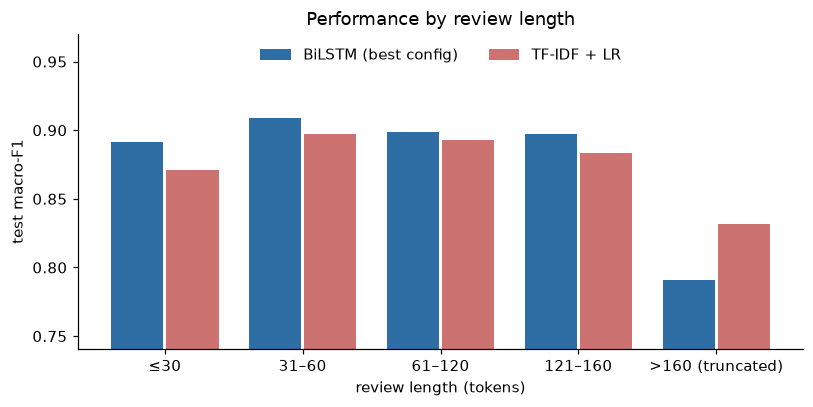

In [17]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
x = np.arange(len(by_len))
ax.bar(x - 0.2, by_len["BiLSTM macro-F1"], 0.38, color="#2f6ea5", label="BiLSTM (best config)")
ax.bar(x + 0.2, by_len["TF-IDF macro-F1"], 0.38, color="#c0504d", alpha=0.8, label="TF-IDF + LR")
ax.set_xticks(x, by_len.index)
ax.set_ylim(by_len[["BiLSTM macro-F1", "TF-IDF macro-F1"]].values.min() - 0.05, 0.97)
ax.set_xlabel("review length (tokens)"); ax.set_ylabel("test macro-F1")
ax.set_title("Performance by review length")
ax.legend(frameon=False, loc="upper center", ncol=2)
plt.tight_layout(); plt.show()

In [18]:
# The most confident mistakes of the best model (first 200 characters)
an["p"] = p_best
wrong = an[an.pred != an.label].copy()
wrong["confidence"] = np.where(wrong.pred == 1, wrong.p, 1 - wrong.p)
pd.set_option("display.max_colwidth", 200)
(wrong.sort_values("confidence", ascending=False)
      .head(8)
      .assign(true=lambda d: d.label.map({1: "pos", 0: "neg"}), text=lambda d: d.Text.str.replace("<br />", " ").str[:200])
      [["true", "confidence", "text"]].round(3))

,true,confidence,text
4030,neg,1.000,Bisquick GF is easy to use. Pancakes and muffins are very tasty. The product is quick and easy to use. It makes my day. Gram
67149,neg,1.000,"I first began using the roasted barley to make a beverage almost thirty years ago while learning Hapkido. It is good for the heart, stabilizes the pancreas, and works as a fat emulsifier. It goes ..."
86377,neg,1.000,"While Welch's fruit snacks are great and tasty, they are easy to go through as it takes about 20 seconds to finish a bag. These vanish very quickly and really arnt worth the 20.00 it costs to buy ..."
145809,pos,0.999,"The cookie was dry, bland, and over just nasty. It's not what I expected especially after having both the chocolate chip cookies and the muscle brownies."
37934,neg,0.999,"I love to feed my kids with goat milk. But to buy it fresh from the farm is so expensive, so this is a great substitute. I started my kids on this when I stopped nursing and they've loved it ever ..."
34887,neg,0.999,These flavors are so subtle (I ate a whole one before I gave to my kids!) but so great to have your tot introduced to such healthy veggies! I've added about half to jarred organic pasta sauce and ...
234629,pos,0.999,"This was the worst tasting popcorn ever. What they have in the red box and twice the price is well worth it. But this, barely passes for corn. No flavor, not a good smell, and tasteless. Styrofoa..."
218378,neg,0.999,"This item was a little pricey for what it was, but it was shipped quickly and was perfect for a last minute birthday gift."


**Where the BiLSTM wins and loses.** On every length band up to 160 tokens, the BiLSTM beats TF-IDF by 0.006–0.020
macro-F1, with the largest margin on short reviews (≤ 30 tokens), where word order and phrasing carry more of the
signal. On reviews longer than 160 tokens it falls behind (0.791 vs 0.832), because they are cut at 160 tokens while
TF-IDF sees the whole text; the verdict of a long review is often in its final lines. Reviews with negation words are
not harder for either model.

The best model finds 84% of negative reviews (2,640 of 3,137), and 79% of the reviews it flags as negative are
negative.

**Many confident "errors" are label noise.** Several of the most confident mistakes are clearly positive text with a
1–2 star rating ("very tasty… It makes my day", "I love to feed my kids with goat milk"), or the reverse ("the worst
tasting popcorn ever" rated 4–5 stars). Star ratings are an imperfect proxy for the sentiment of the text, which caps
the score any model can reach on this data. Others are genuinely mixed reviews, e.g. good taste but poor value.

## 9. Conclusions

1. **Domain beats scale.** Word2Vec embeddings trained on 27M tokens of food reviews outperform GloVe trained on
   6B tokens of general text, both in how they organise sentiment words and in downstream F1 (+0.02 macro-F1, +0.04
   negative-class F1).
2. **Freeze good embeddings.** Frozen domain embeddings matched or beat fine-tuned ones while training fewer
   parameters.
3. **Unlabelled text is the cheapest improvement.** Pretraining on the raw reviews was worth more than doubling the
   labelled training set, and the benefit is largest when labels are scarce.
4. **Check the data before the model.** Duplicate reviews inflate scores by more than the gap between most of the
   embedding choices, and a well-tuned TF-IDF baseline sits within 0.01 of the best neural model.

**Limitations.** Three seeds per configuration on a single fixed split; Word2Vec and the GPU backend are not fully
deterministic, so means moved by up to 0.005 between full runs. Reviews are truncated at 160 tokens, which visibly
hurts the longest reviews. Star ratings are a noisy sentiment label. A pretrained transformer encoder would very likely
outperform every configuration here; this study isolates the effect of the word-embedding layer.